# $H\rightarrow b\bar{b}$ via Sequential Cuts
This notebook consists of two parts: introductory teaching material and the student's independent work. The teaching material provides guidance and serves as a starting point for the independent analysis. It includes examples of data import and the use of provided functions, which are referenced and extended in the independent section.
## Teaching material 
To provide a simple baseline analysis, which can be used to compare a multivariate based analysis to, a set of selection cuts on the kinematic and topological parameters first needs to be optimised. The goal is to apply cuts that maximise the _signal sensitivity_. Cuts should be applied on all variables other than $m_{bb}$, as the $m_{bb}$ distribution is used to evalute the _signal sensitivity_, which is calculated on a bin-by-bin basis from a given distribution ($m_{bb}$ is the most sensitive single variable, so in the absence of a multivariate approach, it is the best single variable to use to distinguish signal from background).

# 2.1 Optimising Cuts

The code below provides an example of how to use the ATLAS simulated data (which contains the signal and all the relevent background processes) to determine a selection of cuts on the kinematic and topoligical parameters to provide an optimal selection to maximise the _signal sensitivity_.

The plot_variable() function can be used to visualise how a particular kinematic or topological event variable is distributed for the various process involved. The code below plots the distributions of a few variables, with the signal (labelled $VH \rightarrow bb$ in the legend) shown in solid red and the other backgrounds shown as filled histograms of various colours, stacked on top of each other. For clarity a red solid line has also been plotted to help identify the shape of the sigal.

In [2]:
# Download the data files if we need them. If you download the repo as a ZIP, 
# this cell is not needed. If running on colab, it will automatically download
# all required data.

from pathlib import Path


data_path = Path('../data-v2/VHbb_data_2jet.csv')
class_path = Path('ucl_masterclass.py')
if not data_path.exists():
    !wget -P ../data-v2/ https://raw.githubusercontent.com/nikitapond/in2HEP/master/data-v2/VHbb_data_2jet.csv
else:
    print("Data file already found")

if not class_path.exists():
    !wget https://raw.githubusercontent.com/nikitapond/in2HEP/master/notebooks/ucl_masterclass.py
else:
    print("Required custom classes already found")

Data file already found
Required custom classes already found


In [3]:
# Importing required libraries
import pandas as pd
import numpy as np
from copy import deepcopy
from ucl_masterclass import *

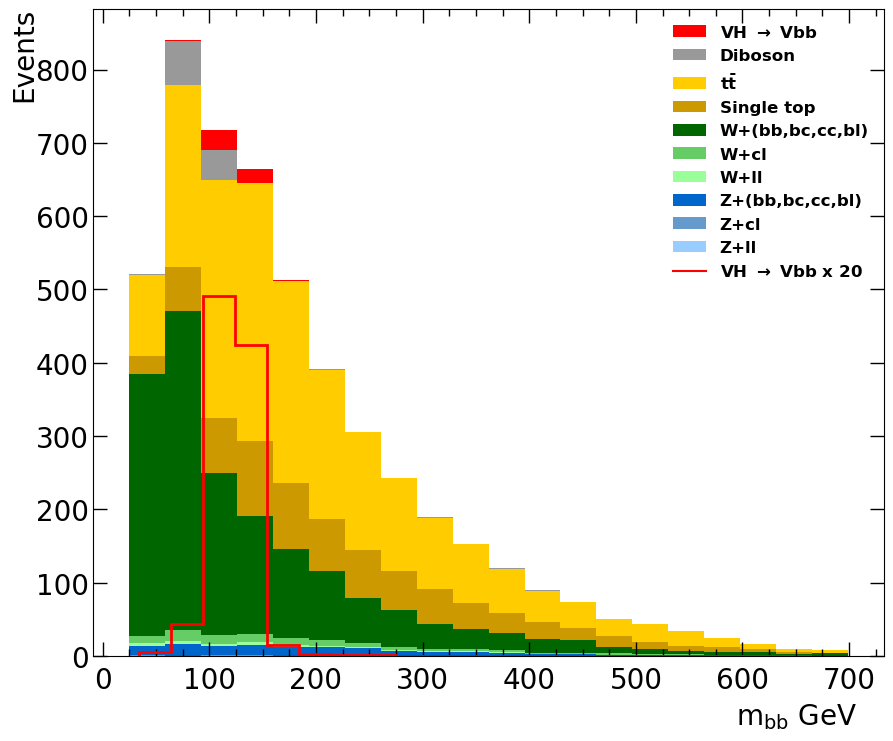

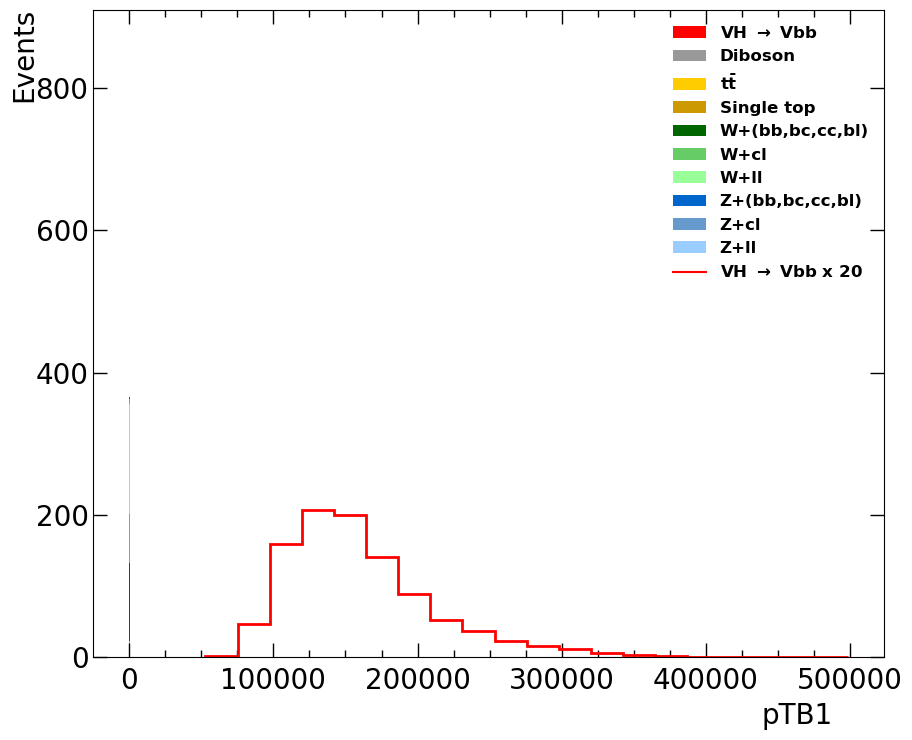

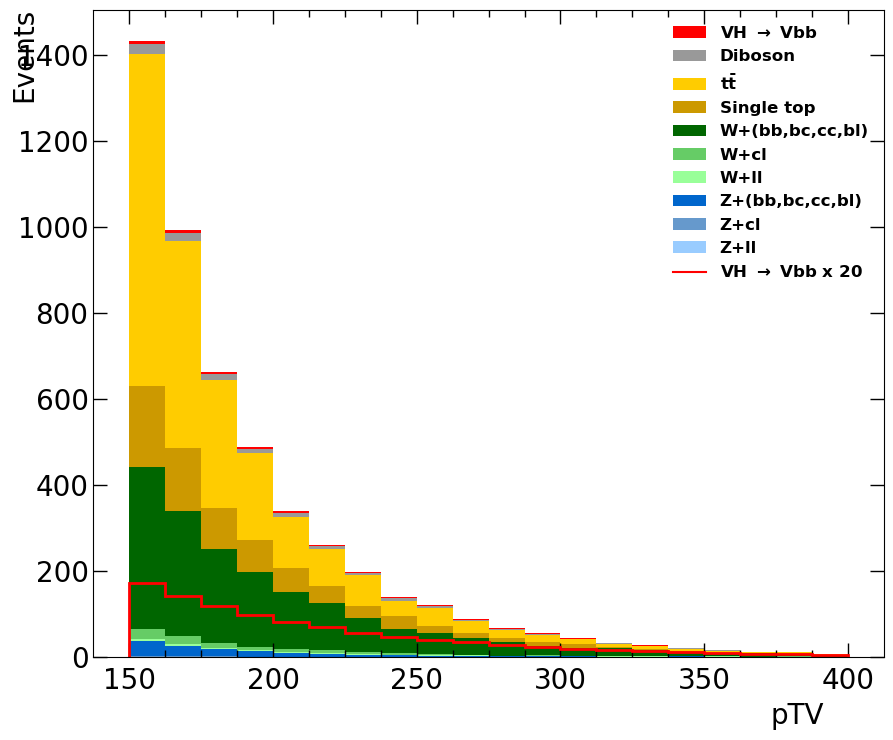

In [4]:
# Load data into a pandas data frame
df = pd.read_csv('../data-v2/VHbb_data_2jet.csv')
df_original = deepcopy(df)

# The plot_variable takes two arguments. First is the data frame used to plot the distributions and
# second is the variable in question.
plot_variable(df,'mBB') # Draw the mBB distribution
plot_variable(df,'pTB1') # Draw the pTB1 distribution
plot_variable(df,'pTV') # Draw the pTV distribution

### Cut-based selection

A suitable technique should be used to choose an optimal and simple selection of sequential cuts on the provided variables (it is not necessary to use all the variables, a subset should suffice), which provides an enhanced selection of signal relative the background. This will provide a baseline, which can be compared to the optimised NN performance later on.

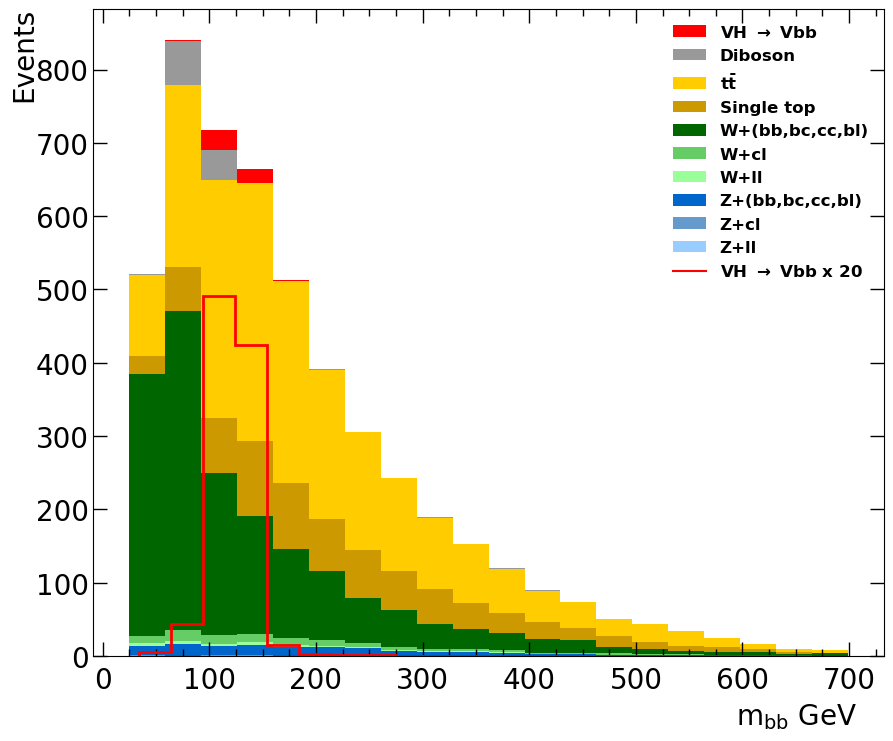

Sensitivity achieved before cuts  1.4990772856082444


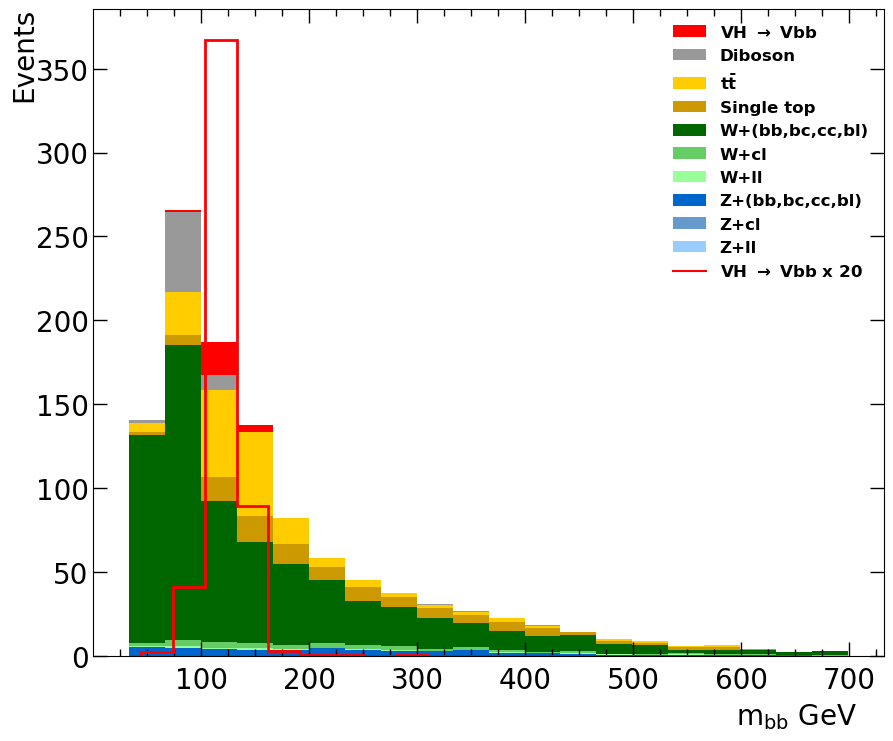

Sensitivity achieved after cuts  1.6303898529992673


In [6]:
# Apply cut
df = df.loc[df["Mtop"] / 1e3 > 250] # divide by 1e3 to convert from MeV to GeV

# The code below plots the mBB distribution before any selection is applied
plot_variable(df_original,'mBB')

# Calculate and output the sensitivity based up the original mBB distribution prior to any selection
# The sensitivity is calculated using the profile likelihood ratio test and Asimov approach
print("Sensitivity achieved before cuts ",sensitivity_cut_based(df_original))

# The code below plots the mBB distribution after the selection has applied
plot_variable(df,'mBB')

# Calculate and output the sensitivity based up the mBB distribution after the selectoin has been applied
print("Sensitivity achieved after cuts ",sensitivity_cut_based(df))

##### Multiple cuts

As well as applying cuts on a single variable, you should also attempt to apply multiple cuts one after the other. Are optimal cuts over two variables at the same point when cutting on a single variable?

**Based upon material originally produced by hackingEducation for use in outreach**  


# Individual Work On Cut-Based analysis
This section is based on the UCL ATLAS teaching tutorial framework. 

In the cut-based baseline, cuts are first applied on kinematic and topological variables to remove as many background events as possible while retaining signal events. After these cuts, the invariant mass of the two b-jets, $m_{BB}$, is used as the final discriminating variable. Since signal events show a "bump" around the Higgs boson mass of approximately 125 GeV, while background events form a smooth distribution,$m_{BB}$ provides strong separation between signal and background. The signal sensitivity is then calculated from the number of signal and background events remaining in the selected region.

Cut-based optimisation workflow:

1. The distributions of candidate input variables are plotted for signal and background processes. These distributions are inspected to determine whether an greater or less than cut is more appropriate for each variable.
2. For each variable, a scan over many possible threshold values is performed in the chosen cut direction. The sensitivity is calculated for every tested threshold, and the optimal cut is identified. The best-performing variable and corresponding threshold are selected by comparing the achieved sensitivities.
3. Additional cuts are then applied cumulatively: only events passing the previous selection(s) are retained. At each stage, the next most effective variable is selected and its optimal threshold is determined, resulting in a sequence of first, second, third, and fourth cuts.
4. The sensitivity is evaluated after each cut in order to quantify the incremental improvement in signal–background separation.

## 1. First single cut
- choose direction from plots
- scan many thresholds
- compute sensitivity
- keep best threshold
- apply best cut

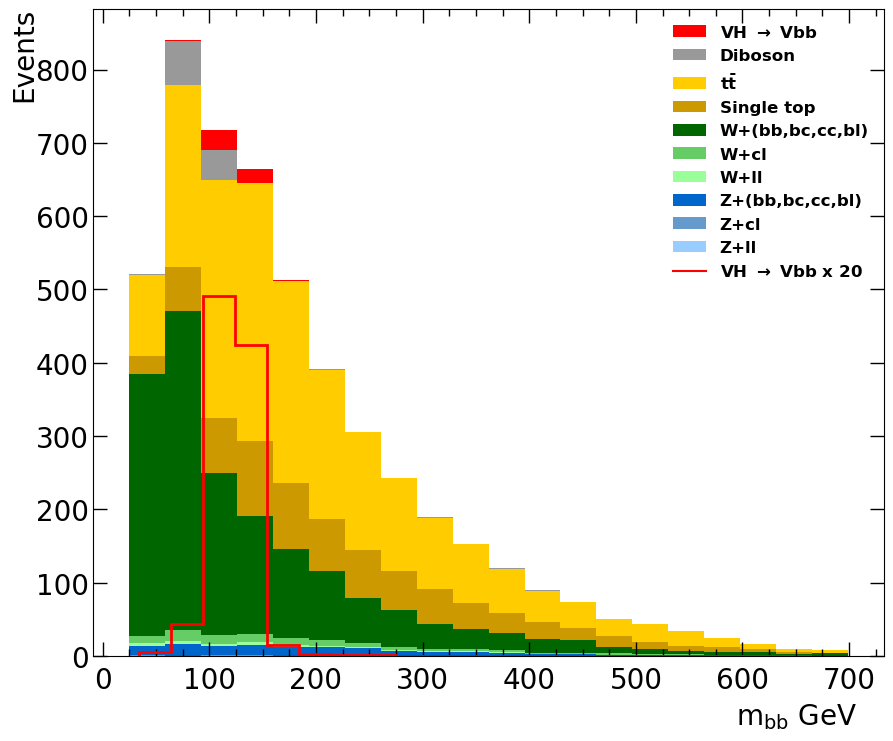

Sensitivity achieved before cuts  1.4990772856082444


In [10]:
# Reset the data frame to the original uncut sample
df = deepcopy(df_original)

# Plot the mBB distribution before any selection is applied
plot_variable(df, 'mBB')

# Calculate and output the baseline sensitivity
print("Sensitivity achieved before cuts ", sensitivity_cut_based(df))

### Plot variables to determine the cut direction

Plotting nJ


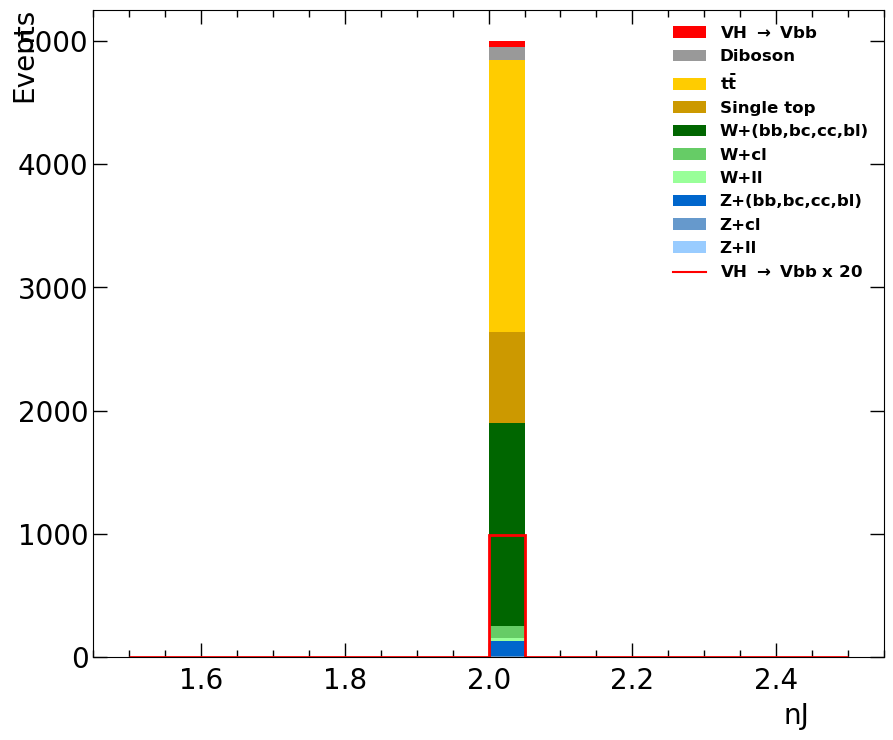

Plotting nTags


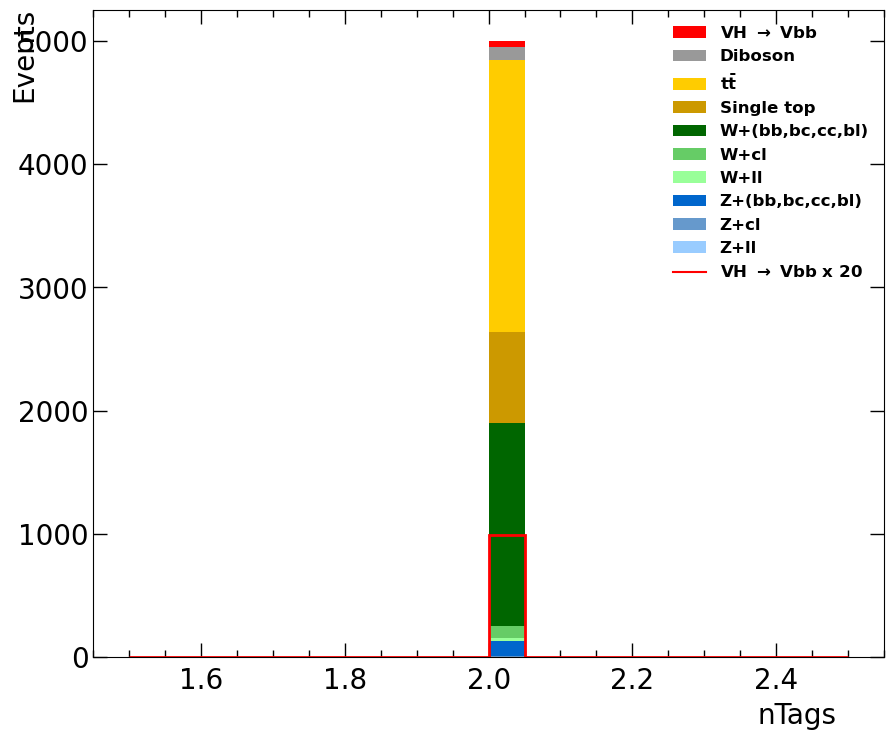

Plotting dRBB


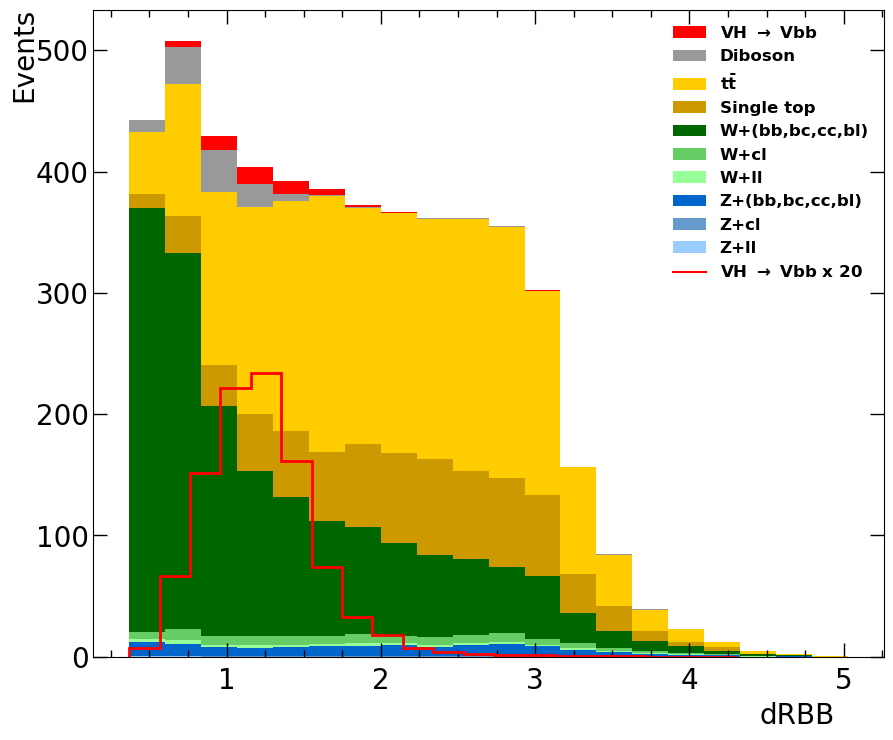

Plotting pTB1


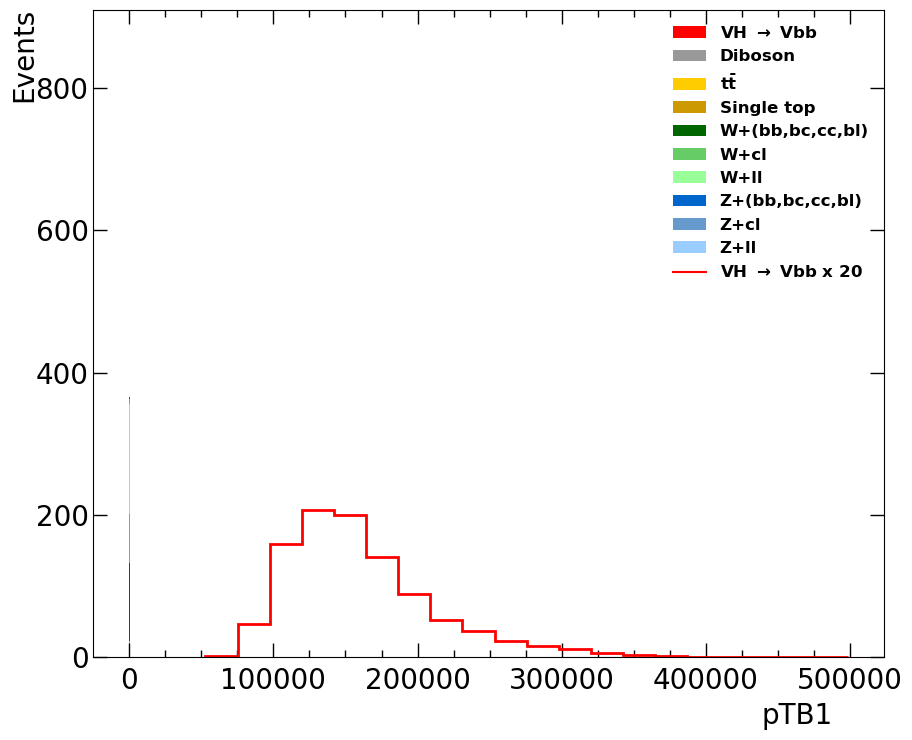

Plotting pTB2


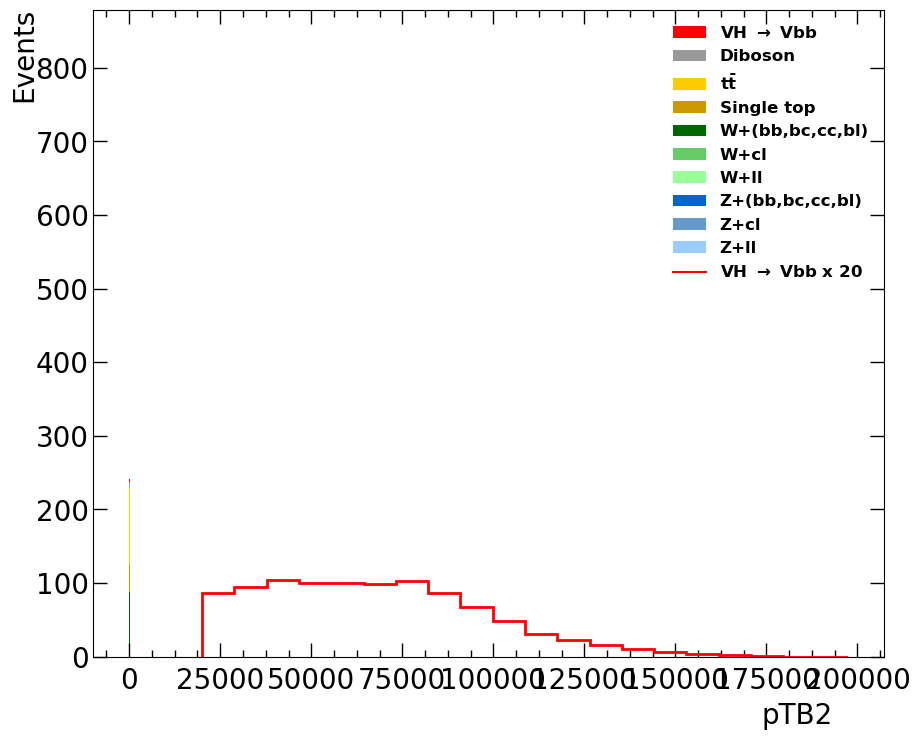

Plotting pTV


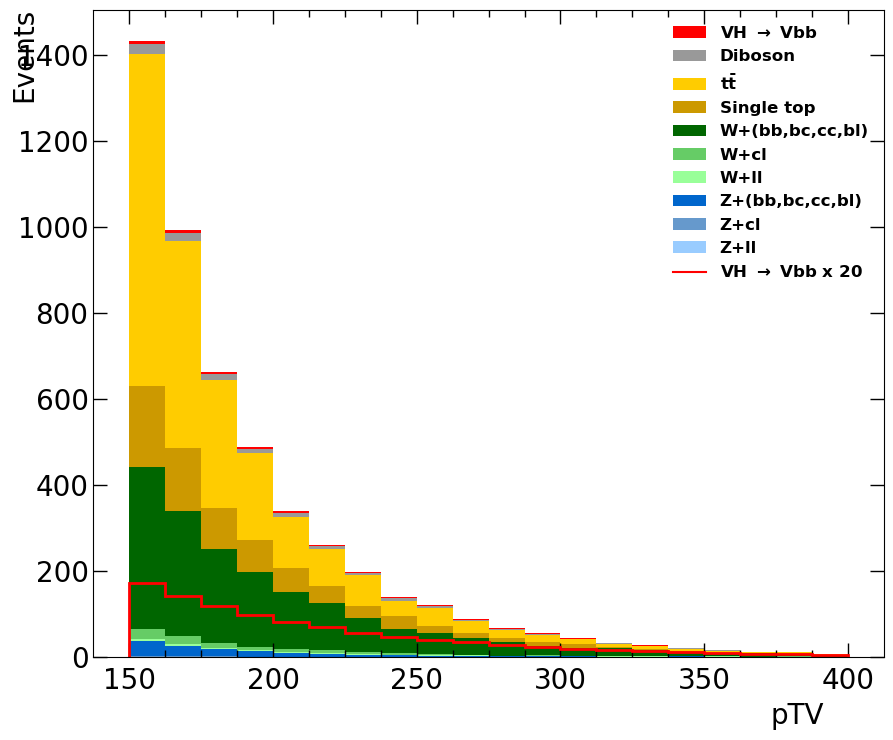

Plotting Mtop


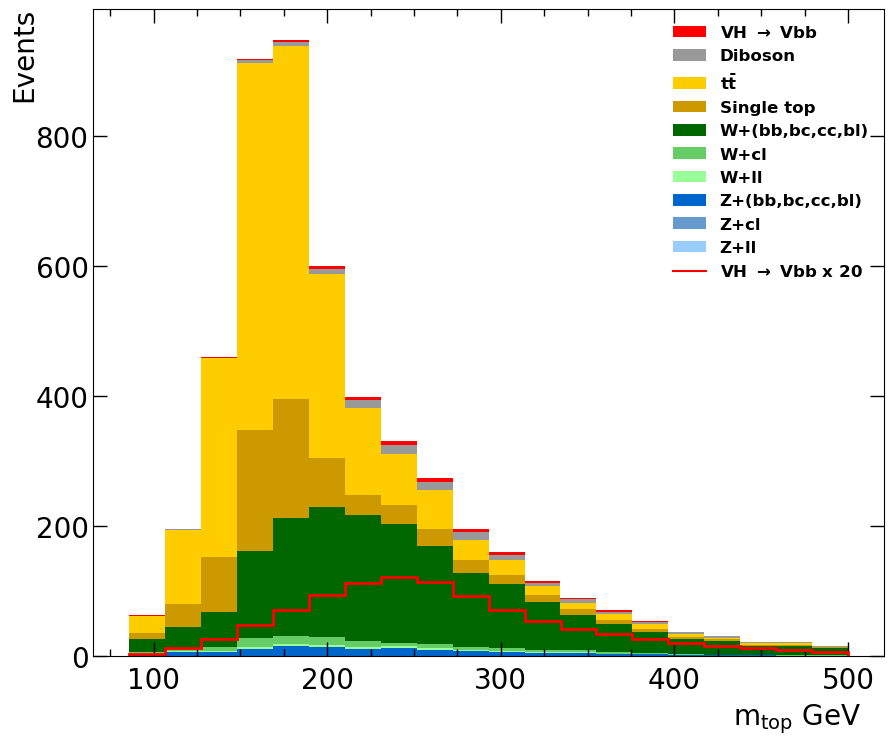

Plotting mTW


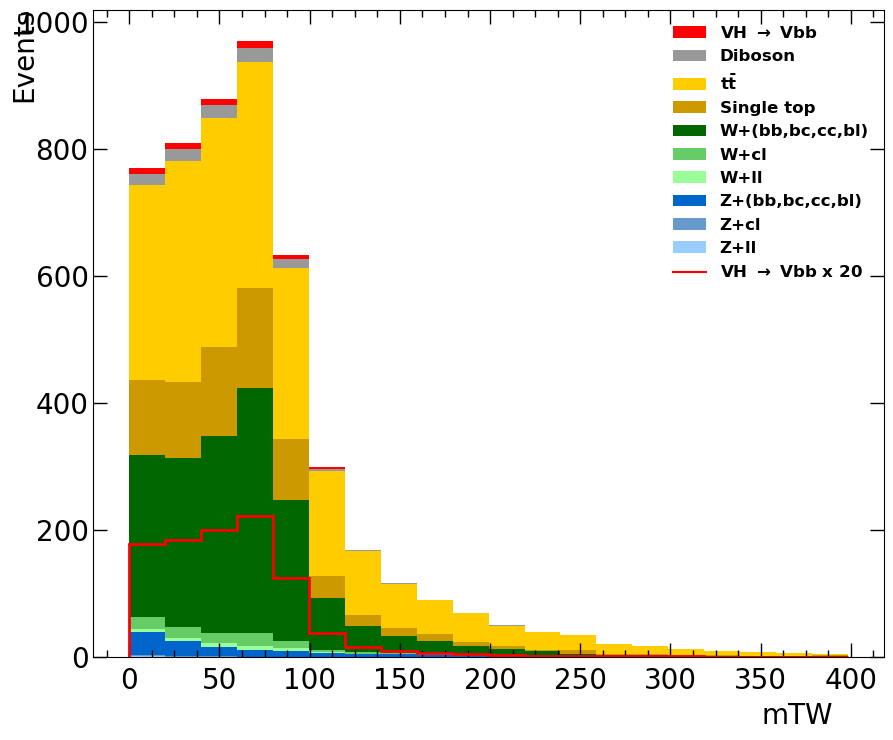

Plotting MET


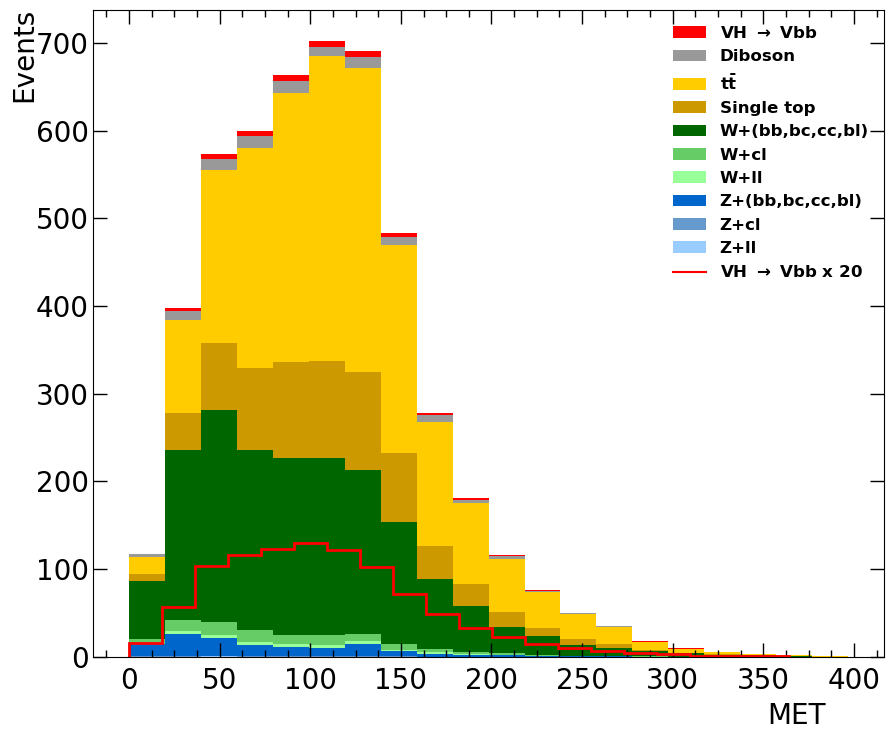

Plotting dYWH


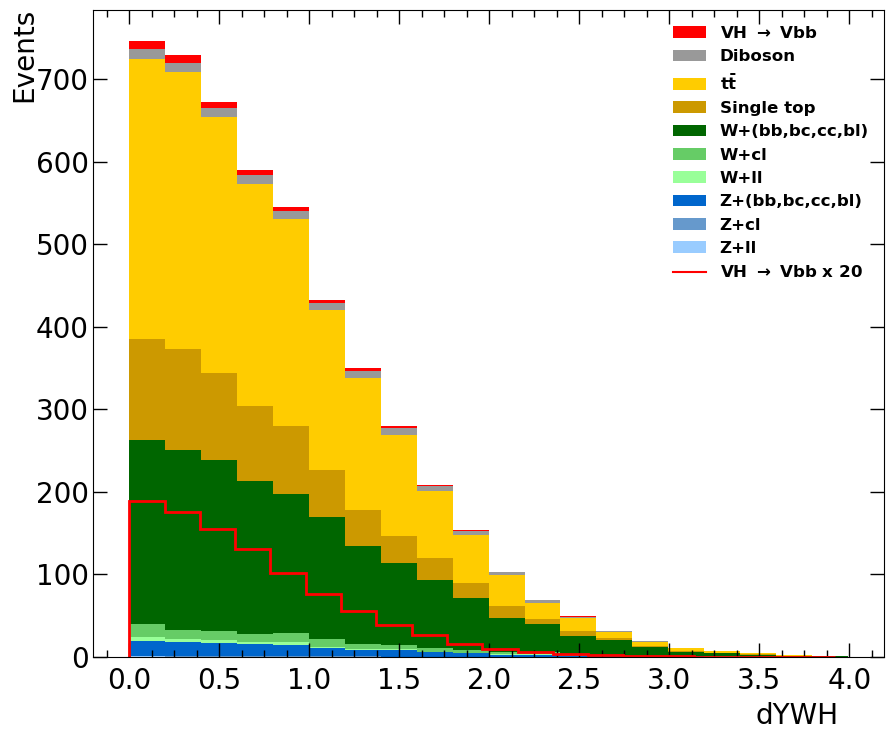

Plotting dPhiVBB


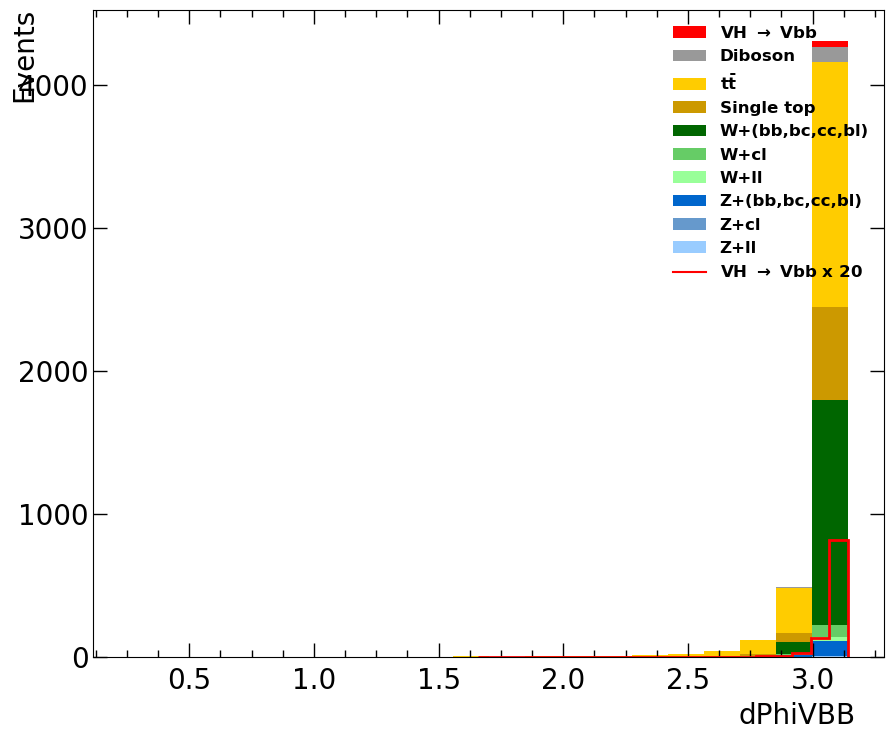

Plotting MV1cB1_cont


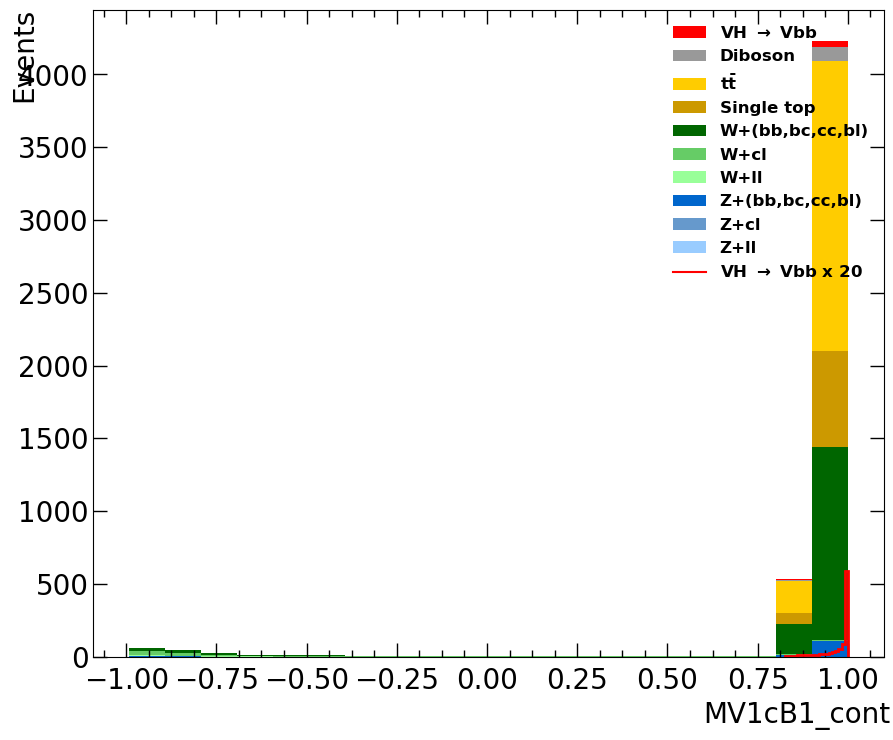

Plotting MV1cB2_cont


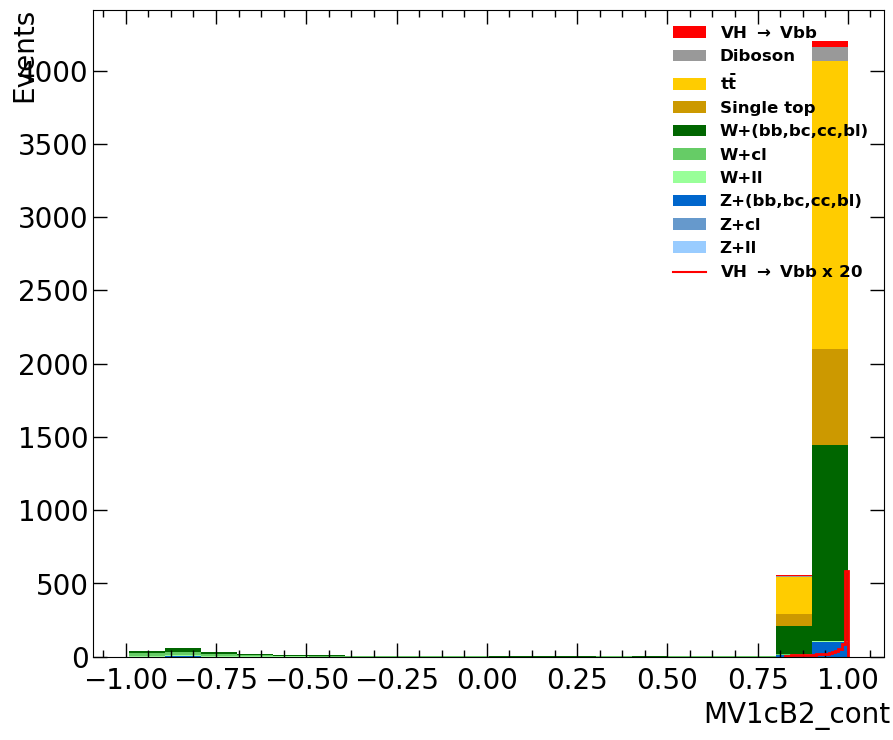

Plotting nTrackJetsOR


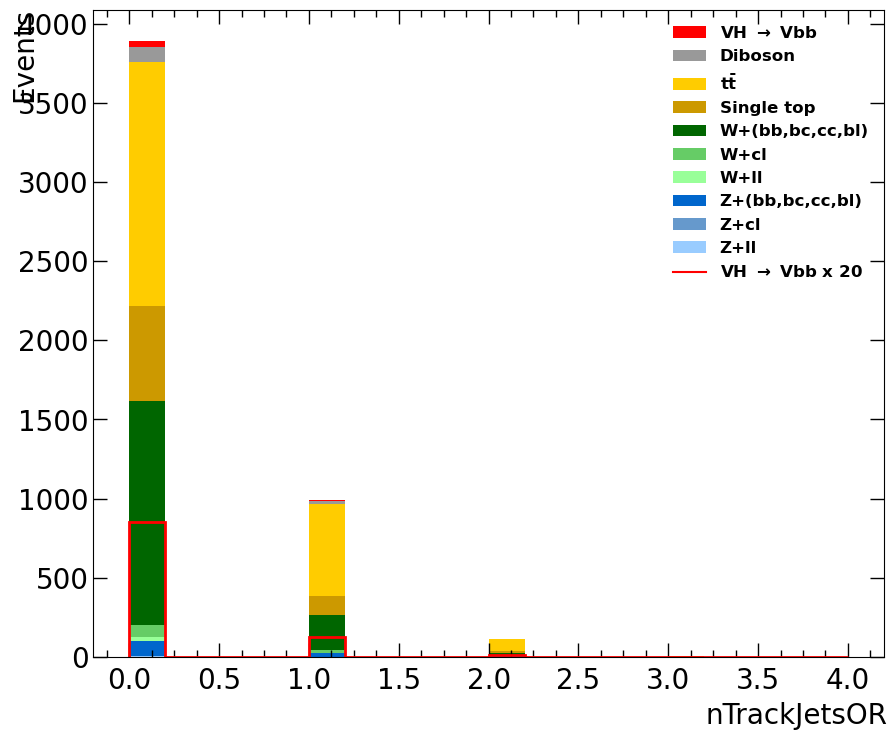

In [12]:


#  list all variables except mBB
variables_to_plot = [
    "nJ",
    "nTags",
    "dRBB",
    "pTB1",
    "pTB2",
    "pTV",
    "Mtop",
    "mTW",
    "MET",
    "dYWH",
    "dPhiVBB",
    "MV1cB1_cont",
    "MV1cB2_cont",
    "nTrackJetsOR"]

# Plot 
for variable in variables_to_plot:
    if variable in df.columns:
        print(f"Plotting {variable}")
        plot_variable(df, variable)

$\textbf{Choose direction of cut:}$

Aim: keep the region where signal dominates over background

signal at high values -> gt

signal at low values -> lt

In this analysis, the choice of cut direction (greater-than or less-than) for each variable was made manually by inspecting the distributions of signal and background. While this approach is intuitive and physically motivated, it introduces a degree of subjectivity. A potential improvement would be to automate this step by scanning both directions for each variable and selecting the one that maximises the signal sensitivity. This would reduce bias from manual choices and ensure that the optimal cut direction is consistent, particularly for variables where the separation is less visually obvious.


In [14]:
def scan_single_cut(df_input, variable, direction, n_points=50, min_quantile=0.05, max_quantile=0.95, min_events=50):
    """
    Scan a single cut on one variable and return the best threshold and sensitivity.

    Inputs:
    Scans between the 5th and 95th percentile, avoid extreme values.
    n_points = tests n possible cut thresholds.
    direction = "gt" means keep variable > threshold
    direction = "lt" means keep variable < threshold

    Returns:
    results_df = sensitivity for all tested thresholds
    best_row = the optimal cut
    """

    
    values = df_input[variable].dropna().values 

   #  Define the range of cut values
    low = np.quantile(values, min_quantile)
    high = np.quantile(values, max_quantile)
    thresholds = np.linspace(low, high, n_points)


    # Apply each possible cut

    results = []

    for threshold in thresholds:
        if direction == "gt":
            df_cut = df_input.loc[df_input[variable] > threshold]
        elif direction == "lt":
            df_cut = df_input.loc[df_input[variable] < threshold]
        else:
            raise ValueError("direction must be 'gt' or 'lt'")

        # Avoid cuts that remove too many events
        if len(df_cut) < min_events:
            continue
            
        # Compute sensitivity after the cut
        try:
            sensitivity = sensitivity_cut_based(df_cut)

            # Skip NaN / inf results
            if not np.isfinite(sensitivity):
                continue

        except Exception:
            continue
            
        # store the results
        results.append({
            "variable": variable,
            "direction": direction,
            "threshold": threshold,
            "n_events": len(df_cut),
            "sensitivity": sensitivity})

    results_df = pd.DataFrame(results)

    if len(results_df) == 0:
        return pd.DataFrame(), None
        
    # Find the best cut
    best_row = results_df.loc[results_df["sensitivity"].idxmax()]
    return results_df, best_row






In [15]:
# Manually define all useful variables except mBB
scan_config = {
    "nJ":("gt", df["nJ"]) ,
    "nTags":("gt", df["nTags"]) ,
    "dRBB": ("lt", df["dRBB"]) ,
    "pTB1": ("gt", df["pTB1"]) ,
    "pTB2": ("gt", df["pTB2"]) ,
    "pTV": ("lt", df["pTV"]) ,
    "Mtop": ("gt", df["Mtop"]) ,
    "mTW": ("lt", df["mTW"]) ,
    "MET": ("lt", df["MET"]) ,
    "dYWH": ("lt", df["dYWH"]) ,
    "dPhiVBB": ("gt", df["dPhiVBB"]) ,
    "MV1cB1_cont": ("gt", df["MV1cB1_cont"]) ,
    "MV1cB2_cont": ("gt", df["MV1cB2_cont"]) ,
    "nTrackJetsOR": ("lt", df["nTrackJetsOR"]) }

# copy dataframe
df_scan = deepcopy(df)


all_best_results = [] #only the best cut from each variable
all_scan_results = {} #full scan output for every variable


for variable, config in scan_config.items():

    direction, _ = config

    # scan the cut for that variable
    results_df, best_row = scan_single_cut(
        df_scan,
        variable,
        direction=direction,
        n_points=60,
        min_events=100)

    all_scan_results[variable] = results_df #save

    if best_row is not None:
        all_best_results.append(best_row)

#make a table of best single cuts
best_single_cuts = pd.DataFrame(all_best_results).sort_values("sensitivity", ascending=False)

print("Best single-variable cuts:")
display(best_single_cuts)

Best single-variable cuts:


,variable,direction,threshold,n_events,sensitivity
14,dRBB,lt,1.366137,71953,1.874429
15,Mtop,gt,209799.219889,72323,1.828969
15,pTB2,gt,49418.330449,67629,1.686972
14,dPhiVBB,gt,3.022434,100155,1.582357
49,mTW,lt,115330.465595,101955,1.543475
42,MV1cB1_cont,gt,0.823392,104389,1.529571
43,MV1cB2_cont,gt,0.821235,104355,1.529432
54,dYWH,lt,1.703321,102545,1.516083
0,pTB1,gt,98573.088281,104739,1.490125
0,nTrackJetsOR,lt,0.016949,92487,1.488354


Best single cut found:
variable           dRBB
direction            lt
threshold      1.366137
n_events          71953
sensitivity    1.874429
Name: 14, dtype: object
Sensitivity achieved before cuts  1.4990772856082444
Sensitivity achieved after best single cut  1.8744294792696046


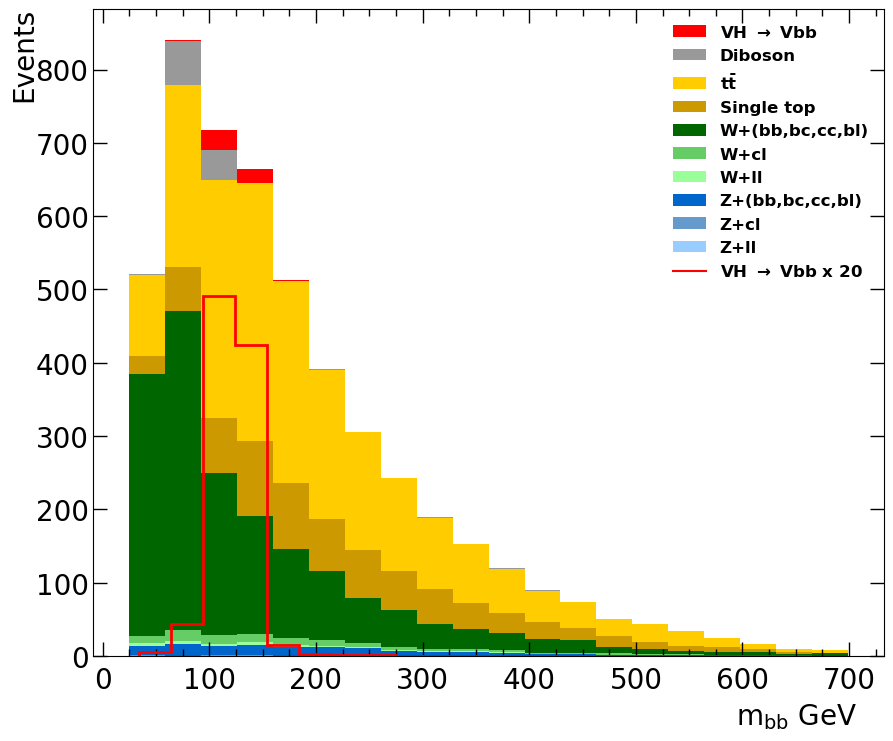

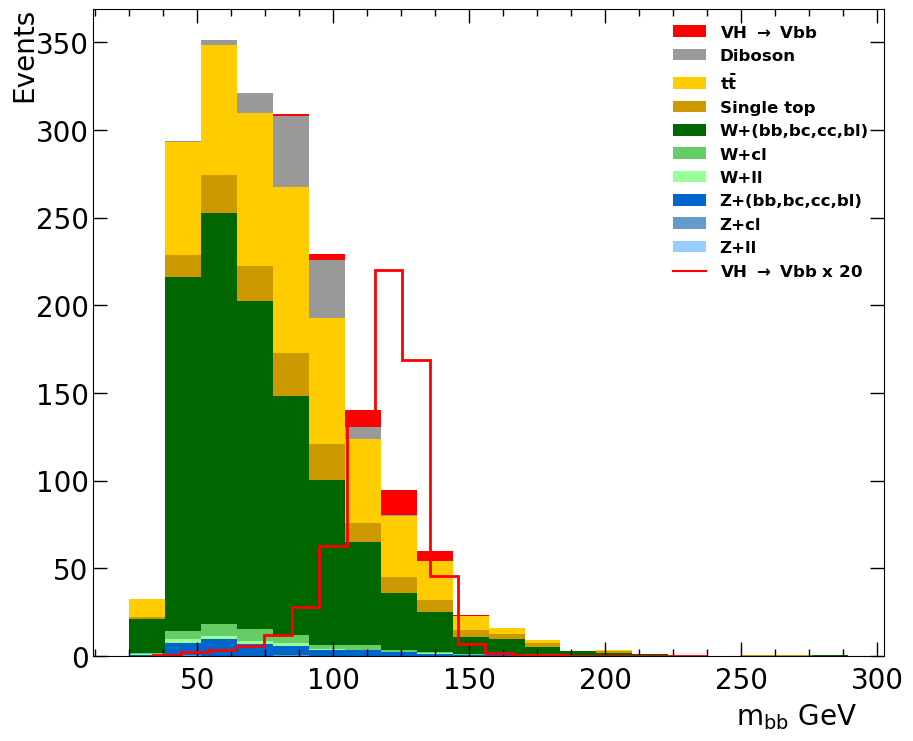

In [16]:
# Select the best variable and cut value
best_single_cut = best_single_cuts.iloc[0]
variable = best_single_cut["variable"]
direction = best_single_cut["direction"]
threshold = best_single_cut["threshold"]

print("Best single cut found:")
print(best_single_cut)


# Apply the cut to the dataset
if direction == "gt":
    df_cut_1 = df.loc[df[variable] > threshold]
else:
    df_cut_1 = df.loc[df[variable] < threshold]

# Compare sensitivities
print("Sensitivity achieved before cuts ", sensitivity_cut_based(df_original))
print("Sensitivity achieved after best single cut ", sensitivity_cut_based(df_cut_1))

# Plot mBB before and after
plot_variable(df_original, 'mBB')
plot_variable(df_cut_1, 'mBB')

After applying the first cut on the dRBB variable, the sensitivity increases from the baseline value of 1.50 to 1.87. This significant improvement demonstrates that the scanning procedure successfully identifies an effective discriminating variable and provides a strong basis for applying subsequent cuts.

## 2. Second cut 
In this section, the goal is to determine the optimal additional cut to apply after the first cut, using the previously defined scanning functions and the sample after the best first cut. Each remaining variable is evaluated by performing a threshold scan, and the cut that yields the highest sensitivity improvement is selected.


In [19]:
# Start from the sample after the best first cut
df_seq = deepcopy(df_cut_1)

# Exclude the variable already used
remaining_scan_config = {k: v for k, v in scan_config.items() 
                         if k != variable and v is not None}



second_cut_results = []

for second_variable, config in remaining_scan_config.items():
    direction, _ = config

    # Scan possible thresholds for the second cut
    results_df, best_row = scan_single_cut(df_seq, second_variable, direction=direction, n_points=60)

    # Store only valid results
    if best_row is not None:
        second_cut_results.append(best_row)

#check if any valid result is found
if len(second_cut_results) == 0:
    print("No valid second cuts found.")
    best_second_cuts = pd.DataFrame()
else:
    best_second_cuts = pd.DataFrame(second_cut_results).sort_values("sensitivity", ascending=False) #highest sensitivity on top
    print("Best second cuts after applying the first cut:")
    display(best_second_cuts)

Best second cuts after applying the first cut:


,variable,direction,threshold,n_events,sensitivity
25,MV1cB2_cont,gt,0.911383,62496,1.931213
15,MV1cB1_cont,gt,0.885700,65280,1.929554
6,Mtop,gt,202201.389036,62518,1.917577
52,mTW,lt,116064.251026,67191,1.897307
0,dPhiVBB,gt,3.007718,68355,1.887399
50,dYWH,lt,1.625105,66662,1.886650
2,pTB2,gt,29959.749285,66076,1.880759
0,pTB1,gt,97775.107813,68355,1.856634
0,nTrackJetsOR,lt,0.016949,61034,1.827334
59,MET,lt,224256.496875,68355,1.815384


Chosen first cut:
variable           dRBB
direction            lt
threshold      1.366137
n_events          71953
sensitivity    1.874429
Name: 14, dtype: object
Chosen second cut:
variable       MV1cB2_cont
direction               gt
threshold         0.911383
n_events             62496
sensitivity       1.931213
Name: 25, dtype: object
Sensitivity achieved before cuts  1.4990772856082444
Sensitivity achieved after one cut  1.8744294792696046
Sensitivity achieved after two cuts  1.9312128314739492


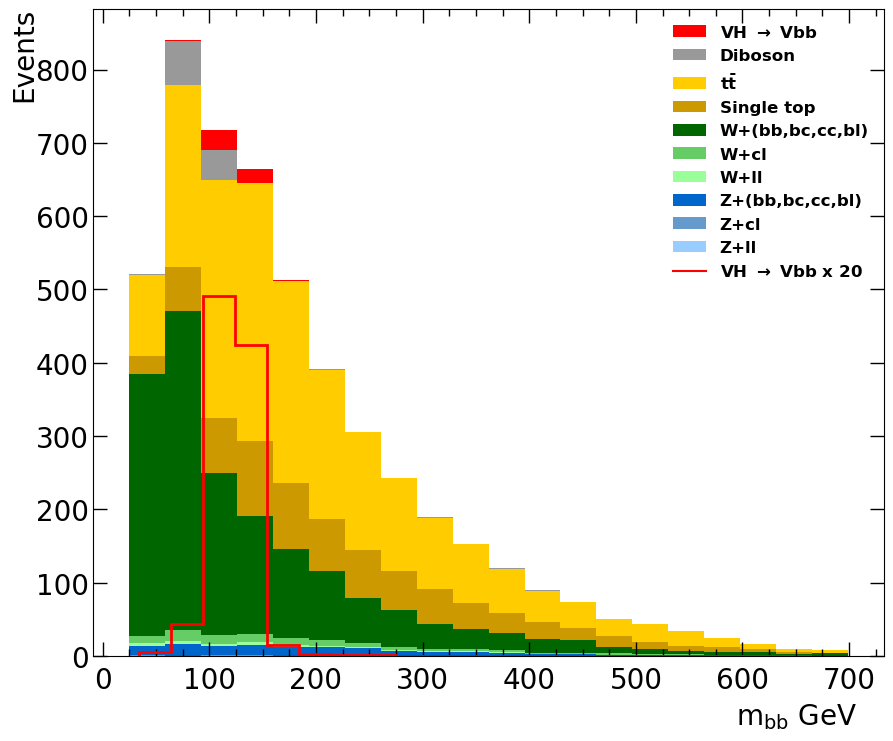

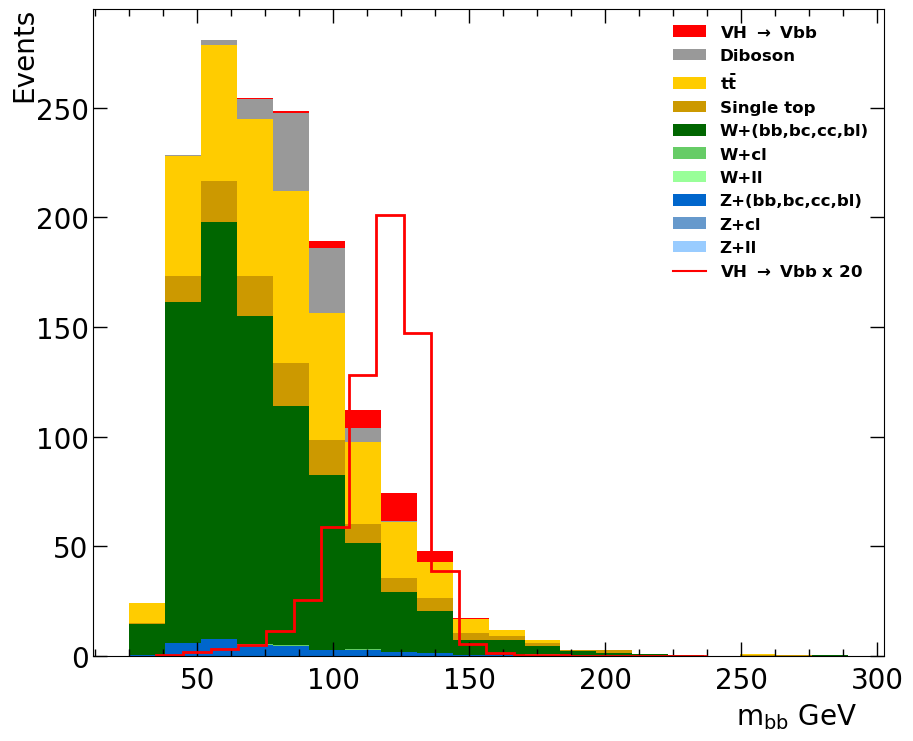

In [20]:
# Take the best second cut
best_second_cut = best_second_cuts.iloc[0]
variable_2 = best_second_cut["variable"]
direction_2 = best_second_cut["direction"]
threshold_2 = best_second_cut["threshold"]

print("Chosen first cut:")
print(best_single_cut)

print("Chosen second cut:")
print(best_second_cut)

# Start from the sample after the first cut
df_cut_2 = deepcopy(df_cut_1)

# Apply the second cut
if direction_2 == "gt":
        df_cut_2 = df_cut_2.loc[df_cut_2[variable_2] > threshold_2]
else:
        df_cut_2 = df_cut_2.loc[df_cut_2[variable_2] < threshold_2]

print("Sensitivity achieved before cuts ", sensitivity_cut_based(df_original))
print("Sensitivity achieved after one cut ", sensitivity_cut_based(df_cut_1))
print("Sensitivity achieved after two cuts ", sensitivity_cut_based(df_cut_2))

# Plot mBB before and after the final two-cut selection
plot_variable(df_original, 'mBB')
plot_variable(df_cut_2, 'mBB')

## 3. Third cut
The same procedure is repeated to determine the optimal third cut.

In [22]:
# Start from the sample after the first two cuts
df_seq_3 = deepcopy(df_cut_2)

# Exclude variables already used
used_variables = {variable, variable_2}
remaining_scan_config_3 = {
    k: v for k, v in scan_config.items()
    if k not in used_variables and v is not None}



third_cut_results = []

for third_variable, config in remaining_scan_config_3.items():
    direction, _ = config

    results_df, best_row = scan_single_cut(
        df_seq_3,
        third_variable,
        direction=direction,
        n_points=60,
        min_events=50)

    if best_row is not None:
        third_cut_results.append(best_row)

best_third_cuts = pd.DataFrame(third_cut_results).sort_values("sensitivity", ascending=False)

print("Best third cuts after applying the first two cuts:")
display(best_third_cuts.reset_index(drop=True))

Best third cuts after applying the first two cuts:


,variable,direction,threshold,n_events,sensitivity
0,Mtop,gt,201522.637579,55374,1.986982
1,mTW,lt,115530.768155,58359,1.963767
2,MV1cB1_cont,gt,0.897316,57571,1.959665
3,dPhiVBB,gt,3.008309,59371,1.953326
4,dYWH,lt,1.719730,58919,1.937403
5,pTB2,gt,32985.607885,56869,1.937103
6,pTB1,gt,97833.326172,59371,1.912294
7,nTrackJetsOR,lt,0.016949,53055,1.880654
8,MET,lt,223753.804688,59371,1.861308
9,pTV,lt,337698.273438,59371,1.846754



Chosen third cut:
variable                Mtop
direction                 gt
threshold      201522.637579
n_events               55374
sensitivity         1.986982
Name: 5, dtype: object
Sensitivity achieved after three cuts  1.9869818875523442


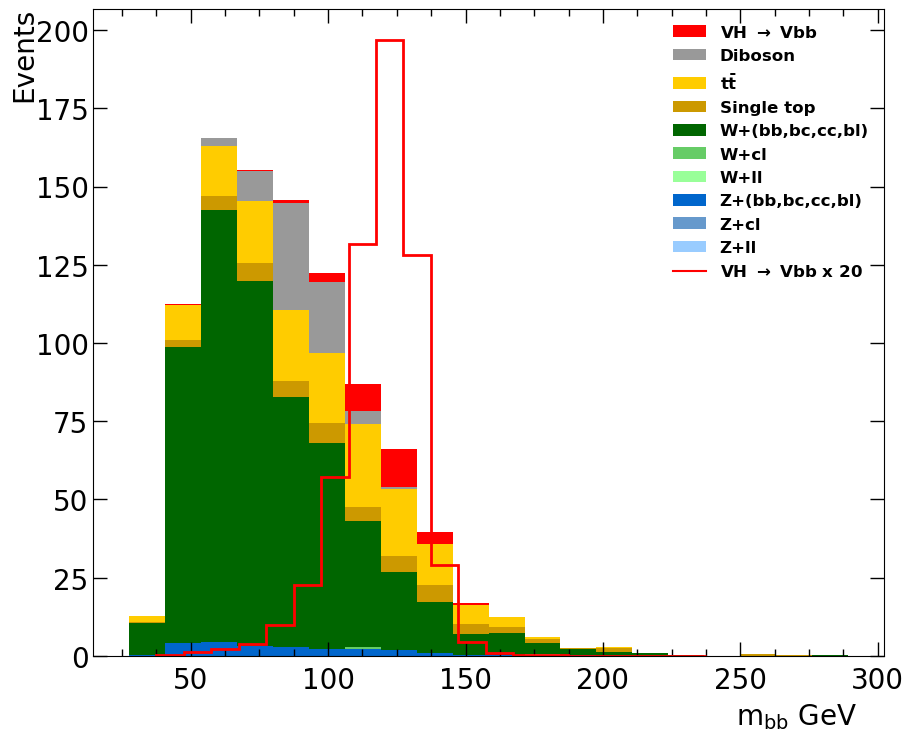

In [23]:
# Take the best third cut
best_third_cut = best_third_cuts.iloc[0]
variable_3 = best_third_cut["variable"]
direction_3 = best_third_cut["direction"]
threshold_3 = best_third_cut["threshold"]


print("\nChosen third cut:")
print(best_third_cut)

# Start from the sample after the second cut
df_cut_3 = deepcopy(df_cut_2)

# Apply the third cut
if direction_3 == "gt":
        df_cut_3 = df_cut_3.loc[df_cut_3[variable_3] > threshold_3]
else:
        df_cut_3 = df_cut_3.loc[df_cut_3[variable_3] < threshold_3]


print("Sensitivity achieved after three cuts ", sensitivity_cut_based(df_cut_3))
plot_variable(df_cut_3, 'mBB')

## 4. Fourth cut

In [25]:
# Start from the sample after the first three cuts
df_seq_4 = deepcopy(df_cut_3)

# Exclude variables already used
used_variables = {variable, variable_2, variable_3}
remaining_scan_config_4 = {
    k: v for k, v in scan_config.items()
    if k not in used_variables and v is not None}



fourth_cut_results = []

for fourth_variable, config in remaining_scan_config_4.items():
    direction, _ = config

    results_df, best_row = scan_single_cut(
        df_seq_4,
        fourth_variable,
        direction=direction,
        n_points=60,
        min_events=50)

    if best_row is not None:
        fourth_cut_results.append(best_row)

best_fourth_cuts = pd.DataFrame(fourth_cut_results).sort_values("sensitivity", ascending=False)

print("Best fourth cuts after applying the first three cuts:")
display(best_fourth_cuts.reset_index(drop=True))

Best fourth cuts after applying the first three cuts:


,variable,direction,threshold,n_events,sensitivity
0,MV1cB1_cont,gt,0.916863,49350,2.023105
1,mTW,lt,115852.701762,51886,1.998750
2,dYWH,lt,1.798621,52605,1.996733
3,dPhiVBB,gt,3.015081,52605,1.996407
4,pTB2,gt,37632.049497,52092,1.980337
5,pTB1,gt,97460.452734,52605,1.971868
6,nTrackJetsOR,lt,0.016949,47086,1.931065
7,MET,lt,227762.176562,52605,1.919978
8,pTV,lt,342125.250000,52605,1.908815



Chosen fourth cut:
variable       MV1cB1_cont
direction               gt
threshold         0.916863
n_events             49350
sensitivity       2.023105
Name: 20, dtype: object
Sensitivity achieved after four cuts  2.023105477890415


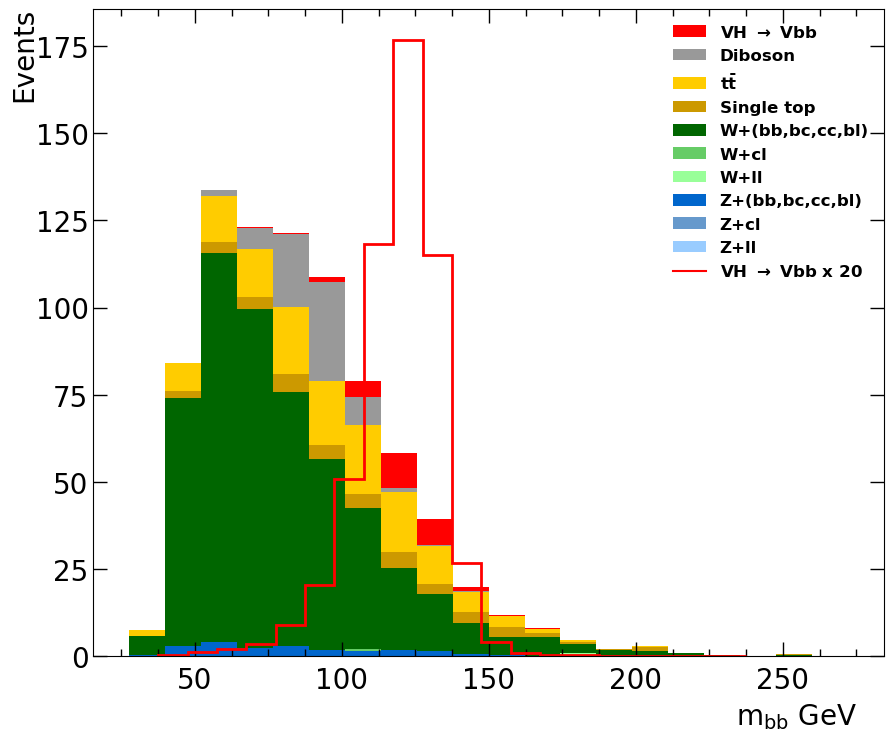

In [26]:
# Take the best fourth cut
best_fourth_cut = best_fourth_cuts.iloc[0]

variable_4 = best_fourth_cut["variable"]
direction_4 = best_fourth_cut["direction"]
threshold_4 = best_fourth_cut["threshold"]


print("\nChosen fourth cut:")
print(best_fourth_cut)

# Start from the sample after the third cut
df_cut_4 = deepcopy(df_cut_3)

# Apply the fourth cut
if direction_4 == "gt":
        df_cut_4 = df_cut_4.loc[df_cut_4[variable_4] > threshold_4]
else:
        df_cut_4 = df_cut_4.loc[df_cut_4[variable_4] < threshold_4]


print("Sensitivity achieved after four cuts ", sensitivity_cut_based(df_cut_4))


plot_variable(df_cut_4, 'mBB')

## 5. Summary 
The sequential cut optimisation shows a steady improvement in sensitivity from 1.50 (baseline) to 2.02 after four cuts, indicating that each additional cut helps suppress background while retaining signal. The most powerful first cut is on dRBB < 1.366, suggesting that selecting events with more collimated b-jets provides the largest initial gain. The optimised cut-based analysis can now be used as a reference benchmark against which the performance of the neural network model will be compared.

In [28]:
summary_df = pd.DataFrame([
    {
        "stage": "baseline",
        "sensitivity": sensitivity_cut_based(df_original)},
    {
        "stage": "1 cut",
        "cut": f"{variable} {direction} {threshold:.4f}",
        "sensitivity": sensitivity_cut_based(df_cut_1)},
    {
        "stage": "2 cuts",
        "cut": f"{variable_2} {direction_2} {threshold_2:.4f}",
        "sensitivity": sensitivity_cut_based(df_cut_2)},
    {
        "stage": "3 cuts",
        "cut": f"{variable_3} {direction_3} {threshold_3:.4f}",
        "sensitivity": sensitivity_cut_based(df_cut_3)},
    {
        "stage": "4 cuts",
        "cut": f"{variable_4} {direction_4} {threshold_4:.4f}",
        "sensitivity": sensitivity_cut_based(df_cut_4)}])

display(summary_df)

,stage,sensitivity,cut
0,baseline,1.499077,NaN
1,1 cut,1.874429,dRBB lt 1.3661
2,2 cuts,1.931213,MV1cB2_cont gt 0.9114
3,3 cuts,1.986982,Mtop gt 201522.6376
4,4 cuts,2.023105,MV1cB1_cont gt 0.9169
